# Exercise 1 ? Multi-Layer Perceptron Classifier

Train and evaluate a three-layer MLP on CIFAR-10. The notebook reports training and test performance and plots training and validation loss and accuracy. All measurements are generated by the executed cells below.

## 1. Model and method

Each 32?32 RGB image is flattened into 3,072 input features. The MLP uses three trainable Linear layers (3,072?512?256?10), ReLU activations, and dropout (`p=0.2`) after the first hidden layer. ReLU provides a nonlinear transformation, dropout regularizes the hidden representation, CrossEntropyLoss is appropriate for the ten-class labels, and Adam updates the weights.

Flattening discards the explicit two-dimensional arrangement of pixels. Unlike a CNN, this MLP does not share filters across image locations, so it must learn useful spatial relationships through its dense weights.

## 2. Imports, reproducibility, and paths

A fixed seed is used for the training/validation split, model initialization, and training data order. Dataset loading is local-only; this notebook will not download CIFAR-10.

In [1]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from IPython.display import Markdown, display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "exercise_1"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Project: D:\AI ML\AI-ML-assessment-cifar10-project
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 3. CIFAR-10 preprocessing and data split

Convert images to tensors and normalize each RGB channel with mean 0.5 and standard deviation 0.5. The 50,000 official training images are split into 45,000 training and 5,000 validation examples using seed 42. The official test set is not loaded until final evaluation.

In [2]:
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 0.001

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
train_val_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=False, transform=transform
)
assert len(train_val_dataset) == 50_000, "Expected the local CIFAR-10 training split."

split_generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset = random_split(
    train_val_dataset, [45_000, 5_000], generator=split_generator
)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
CLASS_NAMES = train_val_dataset.classes
print(f"Training images: {len(train_dataset):,}")
print(f"Validation images: {len(val_dataset):,}")
print("Classes:", CLASS_NAMES)
print("Official test set: reserved for final evaluation")


Training images: 45,000
Validation images: 5,000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Official test set: reserved for final evaluation


## 4. Define the MLP

The Flatten, ReLU, and Dropout modules have no trainable parameters. The three Linear layers are the model's only trainable layers.

In [3]:
class SimpleMLP(nn.Module):
    def __init__(self, input_dim=3 * 32 * 32, hidden_dim=512, second_dim=256, output_dim=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu1 = nn.ReLU()
        self.dropout = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(hidden_dim, second_dim)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(second_dim, output_dim)

    def forward(self, x):
        x = self.flatten(x)
        x = self.dropout(self.relu1(self.fc1(x)))
        x = self.relu2(self.fc2(x))
        return self.fc3(x)

model = SimpleMLP().to(DEVICE)
trainable_layers = [layer for layer in model.modules() if isinstance(layer, nn.Linear)]
assert len(trainable_layers) == 3
TRAINABLE_PARAMETERS = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print("Trainable layers:", len(trainable_layers))
print("Trainable parameters:", f"{TRAINABLE_PARAMETERS:,}")


SimpleMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (relu1): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=10, bias=True)
)
Trainable layers: 3
Trainable parameters: 1,707,274


## 5. Training and validation

Train with CrossEntropyLoss and Adam. At each epoch, record sample-weighted loss and accuracy for both subsets. Validation data are used to monitor generalization; they do not update model weights.

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {key: [] for key in ("train_loss", "train_accuracy", "val_loss", "val_accuracy")}

def run_epoch(loader, training):
    model.train(training)
    loss_sum = 0.0
    correct = 0
    sample_count = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            try:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                if training:
                    optimizer.zero_grad(set_to_none=True)
                logits = model(images)
                loss = criterion(logits, labels)
                if training:
                    loss.backward()
                    optimizer.step()
                batch_size = labels.size(0)
                loss_sum += loss.item() * batch_size
                correct += (logits.argmax(dim=1) == labels).sum().item()
                sample_count += batch_size
            except torch.cuda.OutOfMemoryError as exc:
                if training:
                    optimizer.zero_grad(set_to_none=True)
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                raise RuntimeError(
                    "CUDA ran out of memory. Training stopped without retrying. "
                    "Reduce BATCH_SIZE, recreate the model and optimizer, and restart training."
                ) from exc
    return loss_sum / sample_count, correct / sample_count

training_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader, training=False)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    print(
        f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f}, "
        f"train accuracy {train_accuracy:.4f} | val loss {val_loss:.4f}, "
        f"val accuracy {val_accuracy:.4f}"
    )
training_seconds = time.perf_counter() - training_start
print(f"Training time: {training_seconds:.1f} seconds")


Epoch 1/10 | train loss 1.6844, train accuracy 0.3992 | val loss 1.5573, val accuracy 0.4496


Epoch 2/10 | train loss 1.5018, train accuracy 0.4669 | val loss 1.4784, val accuracy 0.4926


Epoch 3/10 | train loss 1.4110, train accuracy 0.5018 | val loss 1.4382, val accuracy 0.4916


Epoch 4/10 | train loss 1.3429, train accuracy 0.5243 | val loss 1.4257, val accuracy 0.5048


Epoch 5/10 | train loss 1.2807, train accuracy 0.5450 | val loss 1.3912, val accuracy 0.5106


Epoch 6/10 | train loss 1.2271, train accuracy 0.5645 | val loss 1.3957, val accuracy 0.5190


Epoch 7/10 | train loss 1.1827, train accuracy 0.5821 | val loss 1.4169, val accuracy 0.5194


Epoch 8/10 | train loss 1.1278, train accuracy 0.6027 | val loss 1.3863, val accuracy 0.5188


Epoch 9/10 | train loss 1.0864, train accuracy 0.6156 | val loss 1.3898, val accuracy 0.5278


Epoch 10/10 | train loss 1.0508, train accuracy 0.6277 | val loss 1.3774, val accuracy 0.5304
Training time: 131.4 seconds


## 6. Training and validation curves

The first panel shows the required training and validation loss curves. The second panel shows accuracy as a fraction from 0 to 1.

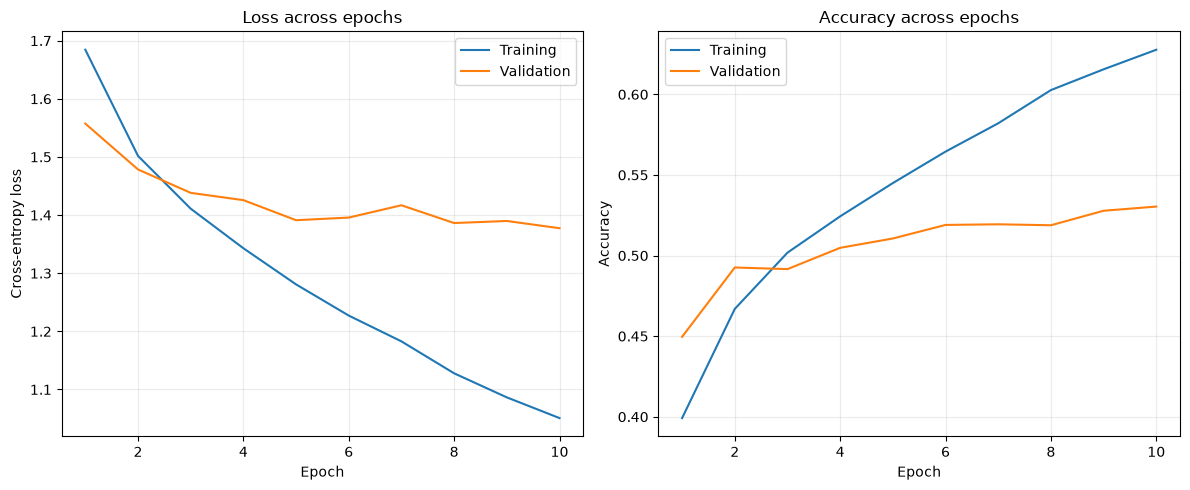

In [5]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(epochs, history["train_loss"], label="Training")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss across epochs", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(epochs, history["train_accuracy"], label="Training")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy across epochs", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "learning_curves.png", dpi=160)
plt.show()


## 7. Final evaluation on the official test set

Load the original 10,000-image test split only after training and validation are complete. Use it once for final performance reporting.

In [6]:
test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=False, transform=transform
)
assert len(test_dataset) == 10_000, "Expected all 10,000 official test images."
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(DEVICE, non_blocking=True))
        y_pred.extend(logits.argmax(dim=1).cpu().tolist())
        y_true.extend(labels.tolist())
test_accuracy = float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))
print(f"Official test accuracy: {test_accuracy:.4f} ({100 * test_accuracy:.2f}%)")


Official test accuracy: 0.5300 (53.00%)


## 8. Classification report and confusion matrix

The classification report gives precision, recall, and F1-score for each class. The confusion matrix shows the number of examples assigned to each predicted class.

              precision    recall  f1-score   support

    airplane       0.58      0.62      0.60      1000
  automobile       0.64      0.60      0.62      1000
        bird       0.45      0.35      0.39      1000
         cat       0.35      0.32      0.34      1000
        deer       0.48      0.42      0.45      1000
         dog       0.42      0.46      0.44      1000
        frog       0.53      0.66      0.59      1000
       horse       0.63      0.60      0.61      1000
        ship       0.64      0.68      0.66      1000
       truck       0.54      0.59      0.57      1000

    accuracy                           0.53     10000
   macro avg       0.53      0.53      0.53     10000
weighted avg       0.53      0.53      0.53     10000



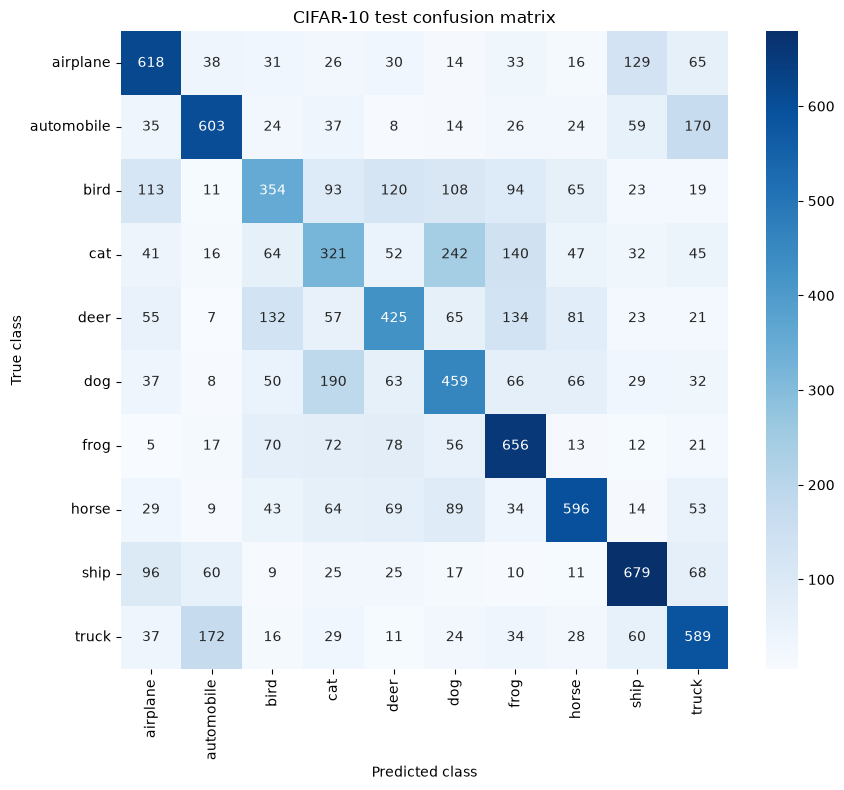

In [7]:
report_text = classification_report(
    y_true, y_pred, target_names=CLASS_NAMES, zero_division=0
)
report = classification_report(
    y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0
)
print(report_text)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax,
)
ax.set(xlabel="Predicted class", ylabel="True class", title="CIFAR-10 test confusion matrix")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "confusion_matrix.png", dpi=160)
plt.show()


## 9. Save measured results

Save the final-epoch model, metric histories, classification report, confusion matrix, and plots under `artifacts/exercise_1/`.

In [8]:
results = {
    "seed": SEED,
    "device": str(DEVICE),
    "trainable_layers": len(trainable_layers),
    "trainable_parameters": TRAINABLE_PARAMETERS,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "split_sizes": {
        "train": len(train_dataset),
        "validation": len(val_dataset),
        "official_test": len(test_dataset),
    },
    "training_seconds": training_seconds,
    "history": history,
    "official_test_accuracy": test_accuracy,
    "classification_report": report,
}
torch.save(
    {
        "model_state_dict": model.cpu().state_dict(),
        "seed": SEED,
        "class_names": CLASS_NAMES,
        "trainable_parameters": TRAINABLE_PARAMETERS,
    },
    ARTIFACT_DIR / "mlp_classifier.pth",
)
model.to(DEVICE)
with (ARTIFACT_DIR / "results.json").open("w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)
with (ARTIFACT_DIR / "classification_report.json").open("w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)
np.savetxt(ARTIFACT_DIR / "confusion_matrix.csv", cm, delimiter=",", fmt="%d")
print("Saved model and results to:", ARTIFACT_DIR)
print("Best validation accuracy:", f"{max(history['val_accuracy']):.4f}",
      "at epoch", int(np.argmax(history['val_accuracy']) + 1))
print("Final training accuracy:", f"{history['train_accuracy'][-1]:.4f}")
print("Final validation accuracy:", f"{history['val_accuracy'][-1]:.4f}")
print("Official test accuracy:", f"{test_accuracy:.4f}")


Saved model and results to: D:\AI ML\AI-ML-assessment-cifar10-project\artifacts\exercise_1
Best validation accuracy: 0.5304 at epoch 10
Final training accuracy: 0.6277
Final validation accuracy: 0.5304
Official test accuracy: 0.5300


## 10. Results and discussion

The measured results are summarized in the saved outputs above. The discussion below is generated from the recorded metrics, not from assumed results.

In [9]:
best_epoch = int(np.argmax(history["val_accuracy"]) + 1)
best_val = float(max(history["val_accuracy"]))
final_train = float(history["train_accuracy"][-1])
final_val = float(history["val_accuracy"][-1])
class_recalls = {name: float(report[name]["recall"]) for name in CLASS_NAMES}
lowest_class = min(class_recalls, key=class_recalls.get)
highest_class = max(class_recalls, key=class_recalls.get)
train_val_gap = final_train - final_val
trend = (
    "The final training accuracy is noticeably higher than the final validation accuracy, which is consistent with overfitting."
    if train_val_gap >= 0.05
    else "The final training and validation accuracies are relatively close, with no large accuracy gap in this run."
)
analysis = f"""### Interpretation

The model reached a best validation accuracy of **{best_val:.2%}** at epoch **{best_epoch}**. Its final training accuracy was **{final_train:.2%}**, final validation accuracy was **{final_val:.2%}**, and official test accuracy was **{test_accuracy:.2%}**. {trend}

On the official test set, recall was lowest for **{lowest_class}** ({class_recalls[lowest_class]:.2%}) and highest for **{highest_class}** ({class_recalls[highest_class]:.2%}). The confusion matrix and class-wise report show which categories were most and least reliably recognized in this run.

Flattening lets the MLP use all input pixels, but it does not preserve the image grid or share a feature detector across locations. That limits its direct use of local spatial patterns. The results are from one seed-42 split, one training run, and no data augmentation; they should be interpreted as this baseline's measured performance rather than a general performance guarantee."""
display(Markdown(analysis))


### Interpretation

The model reached a best validation accuracy of **53.04%** at epoch **10**. Its final training accuracy was **62.77%**, final validation accuracy was **53.04%**, and official test accuracy was **53.00%**. The final training accuracy is noticeably higher than the final validation accuracy, which is consistent with overfitting.

On the official test set, recall was lowest for **cat** (32.10%) and highest for **ship** (67.90%). The confusion matrix and class-wise report show which categories were most and least reliably recognized in this run.

Flattening lets the MLP use all input pixels, but it does not preserve the image grid or share a feature detector across locations. That limits its direct use of local spatial patterns. The results are from one seed-42 split, one training run, and no data augmentation; they should be interpreted as this baseline's measured performance rather than a general performance guarantee.